# Universidad de los Andes
## Maestría en Inteligencia Artificial — Ingeniería de Datos y Características
### Estudio de Caso: Municipio de Montería, Córdoba (Código DIVIPOLA: 23001)

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Maia_Final

Mounted at /content/drive
/content/drive/MyDrive/Maia_Final


## 1. Contexto y Parámetros de Ejecución: Montería (2010–2025)

Este notebook replica de forma estandarizada el *pipeline* de exploración, ingeniería de características y modelado desarrollado en el **notebook base de Ibagué (`73001`)**, con el fin de evaluar la capacidad de generalización del sistema de alertas tempranas en un entorno eco-climático distinto (**Montería, Córdoba — código DIVIPOLA `23001`**). *(La fundamentación teórica detallada de cada método se encuentra documentada en el notebook principal de Ibagué).*

### Parámetros Clave del Experimento
* **Unidad de análisis y periodo:** Municipio-mes para **Montería** (`COD_DPTO_O == 23`, `COD_MUN_O == 1`), ventana **`2010–2025`** (192 meses calendario; **189 meses efectivos** tras rezagos).
* **Datos epidemiológicos (SIVIGILA — Evento 210):** Casos confirmados (laboratorio o nexo epidemiológico) agregados mensualmente según fecha de inicio de síntomas (`INI_SIN`).
* **Datos climáticos (Google Earth Engine):** Reanálisis diario **ECMWF ERA5-Land** (resolución $0,1^\circ \approx 11\text{ km}$) delimitado con polígono municipal **FAO GAUL** (temperatura media, mínima y máxima en $^\circ\text{C}$, precipitación acumulada en $\text{mm}$ y días con lluvia $> 1\text{ mm}$).
* **Ingeniería de variables y objetivo:** Rezagos retrospectivos de 1 a 3 meses ($t-1, t-2, t-3$), media móvil trimestral (`casos_media_movil_3m`) y variable objetivo binaria basada en canal endémico estacional (`exceso_casos = 1` si $\text{Casos}_t > Q_{3,\text{mes}}$).
* **Evaluación y modelado:** Correlación no paramétrica de Spearman ($\rho$), diagnóstico de colinealidad (VIF) y comparación temporal estricta (**Train:** `2010–2018`, **Val:** `2019–2021`, **Test:** `2022–2025`) entre Referencia Estacional, Regresión Logística L2 y XGBoost.

In [3]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

In [4]:
# Rutas con los datos de Montería en Google Drive
RUTA_CARPETA_SIVIGILA = '/content/drive/MyDrive/Maia_Final/Datos-Dengue'
RUTA_CARPETA_CLIMA = '/content/drive/MyDrive/Maia_Final/GEE_Clima_Monteria'

# Validamos que las carpetas existan
print("Existe SIVIGILA?:", os.path.exists(RUTA_CARPETA_SIVIGILA))
print("Existe CLIMA?:", os.path.exists(RUTA_CARPETA_CLIMA))

Existe SIVIGILA?: True
Existe CLIMA?: True


In [5]:
COD_DPTO_MONTERIA = 23       # Córdoba
COD_MUN_MONTERIA = 1         # Montería (DIVIPOLA 23001)
ANIO_INICIO = 2010
ANIO_FIN = 2025

RUTA_ARCHIVOS_SIVIGILA = RUTA_CARPETA_SIVIGILA + '/*'
RUTA_ARCHIVOS_CLIMA = RUTA_CARPETA_CLIMA + '/*.csv'

In [6]:
print("Archivos en GEE_Clima_Monteria:")
archivos_clima_reales = sorted(os.listdir(RUTA_CARPETA_CLIMA))
print(archivos_clima_reales)

print("\nArchivos en Datos-Dengue:")
archivos_sivigila_reales = sorted(os.listdir(RUTA_CARPETA_SIVIGILA))
print(archivos_sivigila_reales)

Archivos en GEE_Clima_Monteria:
['clima_diario_monteria_2010.csv', 'clima_diario_monteria_2011.csv', 'clima_diario_monteria_2012.csv', 'clima_diario_monteria_2013.csv', 'clima_diario_monteria_2014.csv', 'clima_diario_monteria_2015.csv', 'clima_diario_monteria_2016.csv', 'clima_diario_monteria_2017.csv', 'clima_diario_monteria_2018.csv', 'clima_diario_monteria_2019.csv', 'clima_diario_monteria_2020.csv', 'clima_diario_monteria_2021.csv', 'clima_diario_monteria_2022.csv', 'clima_diario_monteria_2023.csv', 'clima_diario_monteria_2024.csv', 'clima_diario_monteria_2025.csv']

Archivos en Datos-Dengue:
['Datos_2007_210.xlsx', 'Datos_2008_210.xlsx', 'Datos_2009_210.xlsx', 'Datos_2010_210.xlsx', 'Datos_2011_210.xlsx', 'Datos_2012_210.xlsx', 'Datos_2013_210.xlsx', 'Datos_2014_210.xlsx', 'Datos_2015_210.xlsx', 'Datos_2016_210.xlsx', 'Datos_2017_210.xlsx', 'Datos_2018_210.xlsx', 'Datos_2019_210.xlsx', 'Datos_2020_210.xlsx', 'Datos_2021_210.xlsx', 'Datos_2022_210.xlsx', 'Datos_2023_210.xlsx', 'Dat

In [7]:
def procesar_sivigila_Monteria(ruta_archivos_sivigila, solo_confirmados=True):
    """
    Carga todos los archivos anuales de SIVIGILA (Excel/CSV), filtra ocurrencia
    en Montería (DIVIPOLA 23001), audita calidad de fechas y calcula agregación mensual.
    """
    archivos = glob.glob(ruta_archivos_sivigila)
    print(f"--> Archivos SIVIGILA detectados: {len(archivos)}")

    registros_Monteria = []
    auditoria_calidad = []

    for archivo in sorted(archivos):
        nombre_arch = os.path.basename(archivo)
        print(f"Procesando: {nombre_arch}...")

        # Lectura según extensión
        if archivo.endswith('.xlsx') or archivo.endswith('.xls'):
            df = pd.read_excel(archivo)
        else:
            df = pd.read_csv(archivo, low_memory=False)

        total_nacional = len(df)

        # Estandarización de códigos DIVIPOLA
        df['COD_DPTO_O'] = pd.to_numeric(df['COD_DPTO_O'], errors='coerce')
        df['COD_MUN_O'] = pd.to_numeric(df['COD_MUN_O'], errors='coerce')

        # Filtro estricto por Ocurrencia en Montería (23001)
        filtro_Monteria = (df['COD_DPTO_O'] == COD_DPTO_MONTERIA) & (df['COD_MUN_O'] == COD_MUN_MONTERIA)
        df_mon = df[filtro_Monteria].copy()

        if len(df_mon) == 0:
            continue

        # Conversión y auditoría de fechas
        df_mon['INI_SIN_DT'] = pd.to_datetime(df_mon['INI_SIN'], errors='coerce')
        df_mon['FEC_NOT_DT'] = pd.to_datetime(df_mon['FEC_NOT'], errors='coerce')

        # Inconsistencias de calidad
        fechas_nulas = df_mon['INI_SIN_DT'].isna().sum()
        inconsistencias_fec = (df_mon['FEC_NOT_DT'] < df_mon['INI_SIN_DT']).sum()

        # Criterio INS: Selección de casos confirmados vs probables
        if 'confirmados' in df_mon.columns:
            casos_conf = (df_mon['confirmados'] == 1).sum()
        else:
            casos_conf = df_mon['TIP_CAS'].isin([2, 3, '2', '3']).sum()

        auditoria_calidad.append({
            'archivo': nombre_arch,
            'total_nacional': total_nacional,
            'total_Monteria': len(df_mon),
            'confirmados_Monteria': casos_conf,
            'tasa_confirmacion_%': round((casos_conf / len(df_mon)) * 100, 2),
            'fechas_invalidas': fechas_nulas,
            'inconsistencia_fec_not_menor': inconsistencias_fec
        })

        # Filtrado de casos válidos
        if solo_confirmados:
            if 'confirmados' in df_mon.columns:
                df_mon = df_mon[df_mon['confirmados'] == 1]
            else:
                df_mon = df_mon[df_mon['TIP_CAS'].isin([2, 3, '2', '3'])]

        # Excluir fechas no válidas
        df_mon = df_mon.dropna(subset=['INI_SIN_DT'])
        registros_Monteria.append(df_mon[['INI_SIN_DT', 'FEC_NOT_DT', 'ANO', 'SEMANA']])

    df_consolidado = pd.concat(registros_Monteria, ignore_index=True)
    df_auditoria = pd.DataFrame(auditoria_calidad)

    # Asignar año-mes según fecha real de inicio de síntomas
    df_consolidado['periodo'] = df_consolidado['INI_SIN_DT'].dt.to_period('M')

    # Agregación mensual de casos
    serie_mensual = df_consolidado.groupby('periodo').size().reset_index(name='casos_dengue')
    serie_mensual['fecha'] = serie_mensual['periodo'].dt.to_timestamp()

    return serie_mensual, df_auditoria

In [8]:
def procesar_clima_Monteria(ruta_archivos_clima):
    """
    Carga series climáticas diarias de Montería (ERA5-Land) y las agrega a nivel mensual.
    """
    archivos = sorted(glob.glob(ruta_archivos_clima))
    print(f"--> Archivos Climáticos detectados: {len(archivos)}")

    if len(archivos) == 0:
        raise FileNotFoundError(
            f"No se encontraron archivos en el patrón: '{ruta_archivos_clima}'. "
            "Revisa la extensión (.csv vs .CSV vs .xlsx) o que la carpeta no esté vacía."
        )

    lista_dfs = []
    for f in archivos:
        print(f"Leyendo clima: {os.path.basename(f)}...")
        if f.lower().endswith('.csv'):
            lista_dfs.append(pd.read_csv(f))
        elif f.lower().endswith(('.xlsx', '.xls')):
            lista_dfs.append(pd.read_excel(f))

    df_clima = pd.concat(lista_dfs, ignore_index=True)
    df_clima['fecha'] = pd.to_datetime(df_clima['fecha'], errors='coerce')
    df_clima = df_clima.dropna(subset=['fecha']).sort_values('fecha')

    df_clima['periodo'] = df_clima['fecha'].dt.to_period('M')

    # Agregación mensual metodológica
    clima_mensual = df_clima.groupby('periodo').agg(
        temp_media=('temp_media_c', 'mean'),
        temp_min_media=('temp_min_c', 'mean'),
        temp_max_media=('temp_max_c', 'mean'),
        precipitacion_total=('precipitacion_mm', 'sum'),
        precipitacion_max_dia=('precipitacion_mm', 'max'),
        dias_con_lluvia=('precipitacion_mm', lambda x: (x > 1.0).sum())
    ).reset_index()

    clima_mensual['fecha'] = clima_mensual['periodo'].dt.to_timestamp()
    return clima_mensual

In [9]:
def construir_dataset_modelado(serie_casos, serie_clima, anio_ini=2010, anio_fin=2025):
    """
    Construye calendario continuo de 192 meses (2010-2025), une fuentes, calcula canales
    endémicos (umbral de exceso Q3) y genera variables rezagadas (189 meses efectivos).
    """
    # 1. Calendario mensual completo para evitar saltos temporales
    rango_completo = pd.date_range(start=f'{anio_ini}-01-01', end=f'{anio_fin}-12-01', freq='MS')
    df_base = pd.DataFrame({'fecha': rango_completo})
    df_base['periodo'] = df_base['fecha'].dt.to_period('M')

    # Cruce con casos (los meses sin casos se imputan en 0)
    df_merge = pd.merge(df_base, serie_casos[['periodo', 'casos_dengue']], on='periodo', how='left')
    df_merge['casos_dengue'] = df_merge['casos_dengue'].fillna(0)

    # Cruce con clima
    df_merge = pd.merge(df_merge, serie_clima.drop(columns=['fecha']), on='periodo', how='left')

    # Mes del año para modelar estacionalidad
    df_merge['mes'] = df_merge['fecha'].dt.month

    # 2. Definición del umbral histórico de exceso (Canal endémico mensual: Percentil 75)
    umbral_estacional = df_merge.groupby('mes')['casos_dengue'].transform(lambda x: x.quantile(0.75))
    df_merge['umbral_q3'] = umbral_estacional
    df_merge['exceso_casos'] = (df_merge['casos_dengue'] > df_merge['umbral_q3']).astype(int)

    # 3. Ingeniería de Rezagos (Lags 1, 2 y 3) para casos y variables climáticas
    features_a_rezagar = ['casos_dengue', 'temp_media', 'temp_min_media', 'precipitacion_total', 'dias_con_lluvia']

    for col in features_a_rezagar:
        for lag in [1, 2, 3]:
            df_merge[f'{col}_lag{lag}'] = df_merge[col].shift(lag)

    # Medias móviles retrospectivas (ventana de 3 meses en retraso)
    df_merge['casos_media_movil_3m'] = df_merge['casos_dengue_lag1'].rolling(window=3).mean()
    df_merge['precip_media_movil_3m'] = df_merge['precipitacion_total_lag1'].rolling(window=3).mean()

    # Eliminación de meses iniciales sin rezago completo
    df_final = df_merge.dropna().reset_index(drop=True)
    return df_final

In [10]:
def ejecutar_analisis_visual(df_modelado):
    """
    Genera gráficos exploratorios y reporte de correlaciones para selección de features en Montería.
    """
    fig, axes = plt.subplots(3, 1, figsize=(14, 15))

    # Gráfico 1: Serie Temporal de Dengue y Umbral de Exceso (Canal Endémico)
    axes[0].plot(df_modelado['fecha'], df_modelado['casos_dengue'], label='Casos Confirmados', color='#1f77b4', lw=2)
    axes[0].plot(df_modelado['fecha'], df_modelado['umbral_q3'], label='Umbral Alerta (Q3 Histórico)', color='#d62728', linestyle='--', lw=1.8)
    axes[0].scatter(df_modelado[df_modelado['exceso_casos'] == 1]['fecha'],
                    df_modelado[df_modelado['exceso_casos'] == 1]['casos_dengue'],
                    color='red', label='Meses con Exceso Detectado', zorder=5)
    axes[0].set_title('Histórico de Casos de Dengue en Montería y Detección de Exceso Mensual', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Casos Mensuales')
    axes[0].legend(loc='upper right')

    # Gráfico 2: Precipitación Rezagada vs Casos
    ax2_twin = axes[1].twinx()
    axes[1].bar(df_modelado['fecha'], df_modelado['precipitacion_total_lag2'], width=20, alpha=0.35, color='#2ca02c', label='Precipitación Acumulada Lag 2 (mm)')
    ax2_twin.plot(df_modelado['fecha'], df_modelado['casos_dengue'], color='#1f77b4', lw=2, label='Casos en t')
    axes[1].set_title('Relación Dinámica: Precipitación Retrasada (t-2 meses) vs Casos de Dengue en Montería (t)', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('Precipitación lag-2 (mm)')
    ax2_twin.set_ylabel('Casos de Dengue')

    # Gráfico 3: Matriz de Correlación de Predictores frente a Variable Objetivo
    columnas_analisis = [
        'casos_dengue', 'casos_dengue_lag1', 'casos_dengue_lag2',
        'temp_media_lag1', 'temp_min_media_lag1', 'temp_media_lag2',
        'precipitacion_total_lag1', 'precipitacion_total_lag2', 'precipitacion_total_lag3',
        'dias_con_lluvia_lag1', 'casos_media_movil_3m'
    ]

    matriz_corr = df_modelado[columnas_analisis].corr(method='spearman')
    sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[2], cbar_kws={'label': 'Spearman Rho'})
    axes[2].set_title('Matriz de Correlación no Paramétrica (Spearman) entre Rezagos y Casos - Montería', fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # Tabla de Priorización de Variables frente a Casos en t
    ranking_corr = matriz_corr['casos_dengue'].drop('casos_dengue').sort_values(ascending=False)
    print("\n" + "="*60)
    print("RANKING DE PRIORIZACIÓN DE PREDICTORES - MONTERÍA (CORRELACIÓN CON CASOS EN t)")
    print("="*60)
    for variable, rho in ranking_corr.items():
        print(f" - {variable:<30}: Rho = {rho:+.3f}")
    print("="*60)

In [11]:
# Procesamos el clima de Montería
print("Iniciando procesamiento climático...")
df_clima = procesar_clima_Monteria(RUTA_ARCHIVOS_CLIMA)

# Validación
print("\nMuestra de datos climáticos mensuales (Montería):")
display(df_clima.head())
print("\nDimensiones de clima:", df_clima.shape)

Iniciando procesamiento climático...
--> Archivos Climáticos detectados: 16
Leyendo clima: clima_diario_monteria_2010.csv...
Leyendo clima: clima_diario_monteria_2011.csv...
Leyendo clima: clima_diario_monteria_2012.csv...
Leyendo clima: clima_diario_monteria_2013.csv...
Leyendo clima: clima_diario_monteria_2014.csv...
Leyendo clima: clima_diario_monteria_2015.csv...
Leyendo clima: clima_diario_monteria_2016.csv...
Leyendo clima: clima_diario_monteria_2017.csv...
Leyendo clima: clima_diario_monteria_2018.csv...
Leyendo clima: clima_diario_monteria_2019.csv...
Leyendo clima: clima_diario_monteria_2020.csv...
Leyendo clima: clima_diario_monteria_2021.csv...
Leyendo clima: clima_diario_monteria_2022.csv...
Leyendo clima: clima_diario_monteria_2023.csv...
Leyendo clima: clima_diario_monteria_2024.csv...
Leyendo clima: clima_diario_monteria_2025.csv...

Muestra de datos climáticos mensuales (Montería):


,periodo,temp_media,temp_min_media,temp_max_media,precipitacion_total,precipitacion_max_dia,dias_con_lluvia,fecha
0,2010-01,28.001117,24.588050,32.987898,21.333068,6.586426,4,2010-01-01
1,2010-02,28.921468,25.861279,34.257332,46.394021,8.219512,12,2010-02-01
2,2010-03,27.931955,25.498263,32.007727,152.882257,17.861638,25,2010-03-01
3,2010-04,27.429519,24.822366,31.361058,179.637047,16.857022,30,2010-04-01
4,2010-05,27.024343,24.512113,30.869443,274.625889,21.668075,29,2010-05-01



Dimensiones de clima: (192, 8)


In [12]:
# Resumen estadístico global de los 192 meses (2010-2025) - Montería
print("=== ESTADÍSTICAS DESCRIPTIVAS CLIMA MONTERÍA (2010-2025) ===")
display(df_clima[['temp_media', 'temp_min_media', 'temp_max_media',
                  'precipitacion_total', 'dias_con_lluvia']].describe().round(2))

# Promedio histórico por mes calendario (1 a 12) para ver el ciclo anual
df_clima['mes'] = df_clima['fecha'].dt.month
print("\n=== CICLO ESTACIONAL PROMEDIO POR MES (MONTERÍA) ===")
display(df_clima.groupby('mes')[['temp_media', 'temp_min_media',
                                 'precipitacion_total', 'dias_con_lluvia']].mean().round(2))

=== ESTADÍSTICAS DESCRIPTIVAS CLIMA MONTERÍA (2010-2025) ===


,temp_media,temp_min_media,temp_max_media,precipitacion_total,dias_con_lluvia
count,192.00,192.00,192.00,192.00,192.00
mean,27.09,24.23,31.33,165.26,23.02
std,0.97,0.73,1.57,90.78,8.62
min,24.90,22.69,28.55,5.69,0.00
25%,26.34,23.68,30.22,77.70,20.00
50%,26.94,24.12,30.78,189.16,27.00
75%,27.62,24.70,31.97,233.17,29.00
max,29.82,26.42,35.87,373.16,31.00



=== CICLO ESTACIONAL PROMEDIO POR MES (MONTERÍA) ===


,temp_media,temp_min_media,precipitacion_total,dias_con_lluvia
mes,,,,
1,27.47,24.04,36.28,9.44
2,28.53,25.01,28.06,7.62
3,28.37,25.14,82.08,16.31
4,27.65,24.79,170.94,26.12
5,27.03,24.47,264.19,28.81
6,26.79,24.17,234.80,27.62
7,26.86,24.13,219.74,27.88
8,26.75,24.03,219.41,28.50
9,26.61,23.99,224.36,28.50


In [ ]:
# Procesamos epidemiología de Montería
print("Iniciando procesamiento SIVIGILA (Esto puede tardar varios minutos)...")
df_casos, df_auditoria = procesar_sivigila_Monteria(RUTA_ARCHIVOS_SIVIGILA, solo_confirmados=True)

# Validación
print("\nReporte de Auditoría de Calidad (Montería):")
display(df_auditoria)

print("\nMuestra de casos mensuales confirmados:")
display(df_casos.head())

Iniciando procesamiento SIVIGILA (Esto puede tardar varios minutos)...
--> Archivos SIVIGILA detectados: 19
Procesando: Datos_2007_210.xlsx...


/tmp/ipykernel_3037/60934703.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['INI_SIN_DT'] = pd.to_datetime(df_mon['INI_SIN'], errors='coerce')
/tmp/ipykernel_3037/60934703.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['FEC_NOT_DT'] = pd.to_datetime(df_mon['FEC_NOT'], errors='coerce')


Procesando: Datos_2008_210.xlsx...


/tmp/ipykernel_3037/60934703.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['INI_SIN_DT'] = pd.to_datetime(df_mon['INI_SIN'], errors='coerce')
/tmp/ipykernel_3037/60934703.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['FEC_NOT_DT'] = pd.to_datetime(df_mon['FEC_NOT'], errors='coerce')


Procesando: Datos_2009_210.xlsx...


/tmp/ipykernel_3037/60934703.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['INI_SIN_DT'] = pd.to_datetime(df_mon['INI_SIN'], errors='coerce')
/tmp/ipykernel_3037/60934703.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['FEC_NOT_DT'] = pd.to_datetime(df_mon['FEC_NOT'], errors='coerce')


... (31 outputs left out)

/tmp/ipykernel_3037/60934703.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['INI_SIN_DT'] = pd.to_datetime(df_mon['INI_SIN'], errors='coerce')
/tmp/ipykernel_3037/60934703.py:37: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_mon['FEC_NOT_DT'] = pd.to_datetime(df_mon['FEC_NOT'], errors='coerce')


,archivo,total_nacional,total_Monteria,confirmados_Monteria,tasa_confirmacion_%,fechas_invalidas,inconsistencia_fec_not_menor
0,Datos_2007_210.xlsx,35074,126,105,83.33,0,33
1,Datos_2008_210.xlsx,32793,222,193,86.94,0,43
2,Datos_2009_210.xlsx,45345,50,48,96.00,0,5
3,Datos_2010_210.xlsx,147224,114,4,3.51,0,24
4,Datos_2011_210.xlsx,29386,354,278,78.53,0,63
5,Datos_2012_210.xlsx,52467,387,346,89.41,0,99
6,Datos_2013_210.xlsx,122441,615,485,78.86,0,395
7,Datos_2014_210.xlsx,105356,1594,1190,74.65,0,389
8,Datos_2015_210.xlsx,95023,624,354,56.73,0,147
9,Datos_2016_210.xlsx,100117,350,190,54.29,1,106



Muestra de casos mensuales confirmados:


,periodo,casos_dengue,fecha
0,2006-05,1,2006-05-01
1,2006-12,2,2006-12-01
2,2007-01,15,2007-01-01
3,2007-02,5,2007-02-01
4,2007-03,6,2007-03-01


## 2. Clima y SIVIGILA en Montería (2010–2025)

A partir de la ejecución de los módulos de extracción y limpieza para **Montería (DIVIPOLA `23001`)**, se verificaron los siguientes resultados de cobertura y calidad:

1. **Consolidación Climática (`ERA5-Land` / GEE):**
   * Se integraron **16 archivos anuales (`2010–2025`)**, consolidando exactamente **192 meses continuos** sin valores faltantes (`(192, 8)`).
   * A diferencia del régimen bimodal andino, Montería presenta un **clima cálido tropical de sabana (valle del río Sinú)** con temperaturas medias mensuales estables entre **26,0C  y 28,9C**, temperaturas mínimas entre **23,6C y 25,9C**.

2. **Auditoría Epidemiológica (`SIVIGILA` Evento 210):**
   * En el periodo de estudio **`2010–2025`**, se identificaron **20.181 registros notificados** con ocurrencia en Montería, de los cuales **12.375 casos ($61,32\,\%$)** cuentan con confirmación diagnóstica estricta (laboratorio o nexo epidemiológico).
   * **Heterogeneidad en la tasa de confirmación:** Mientras años como 2012 ($89,41\,\%$) o 2011 ($78,53\,\%$) presentan alta confirmación, en **2010** solo se confirmó el **$3,51\,\%$** (4 de 114 registros) y en **2025** el **$46,78\,\%$** (2.306 confirmados de 4.929 notificados), lo cual ratifica la importancia de reportar la proporción confirmada como variable de control metodológico.
   * **Inconsistencias temporales depuradas:** Se detectó **1 fecha de inicio de síntomas inválida** (en el archivo 2016) y **4.971 registros** donde la fecha de notificación (`FEC_NOT`) fue anterior a la fecha de inicio de síntomas (`INI_SIN`) en `2010–2025` (concentrados principalmente en 2025 con 1.143 casos), los cuales fueron aislados mediante agrupación estricta por `INI_SIN`.
   * **Ciclos epidémicos históricos en Montería:** Los mayores volúmenes de casos confirmados se registraron en **2014 (1.190 casos)**, **2019 (1.255 casos)**, **2021 (1.203 casos)**, **2024 (1.619 casos)** y **2025 (2.306 casos)**.

Generando dataset final con rezagos (Lags) para Montería...

Dimensiones del Dataset de Modelado: (189, 29)


,fecha,periodo,casos_dengue,temp_media,temp_min_media,temp_max_media,precipitacion_total,precipitacion_max_dia,dias_con_lluvia,mes,...,temp_min_media_lag2,temp_min_media_lag3,precipitacion_total_lag1,precipitacion_total_lag2,precipitacion_total_lag3,dias_con_lluvia_lag1,dias_con_lluvia_lag2,dias_con_lluvia_lag3,casos_media_movil_3m,precip_media_movil_3m
0,2010-04-01,2010-04,0.0,27.429519,24.822366,31.361058,179.637047,16.857022,30,4,...,25.861279,24.588050,152.882257,46.394021,21.333068,25.0,12.0,4.0,0.333333,73.536449
1,2010-05-01,2010-05,0.0,27.024343,24.512113,30.869443,274.625889,21.668075,29,5,...,25.498263,25.861279,179.637047,152.882257,46.394021,30.0,25.0,12.0,0.333333,126.304442
2,2010-06-01,2010-06,1.0,26.344470,23.915340,30.111137,288.524876,21.674094,30,6,...,24.822366,25.498263,274.625889,179.637047,152.882257,29.0,30.0,25.0,0.333333,202.381731
3,2010-07-01,2010-07,2.0,26.040553,23.669860,29.679634,343.562382,25.593299,30,7,...,24.512113,24.822366,288.524876,274.625889,179.637047,30.0,29.0,30.0,0.333333,247.595938
4,2010-08-01,2010-08,0.0,26.034105,23.585311,29.944889,330.391635,24.024810,31,8,...,23.915340,24.512113,343.562382,288.524876,274.625889,30.0,30.0,29.0,1.000000,302.237716


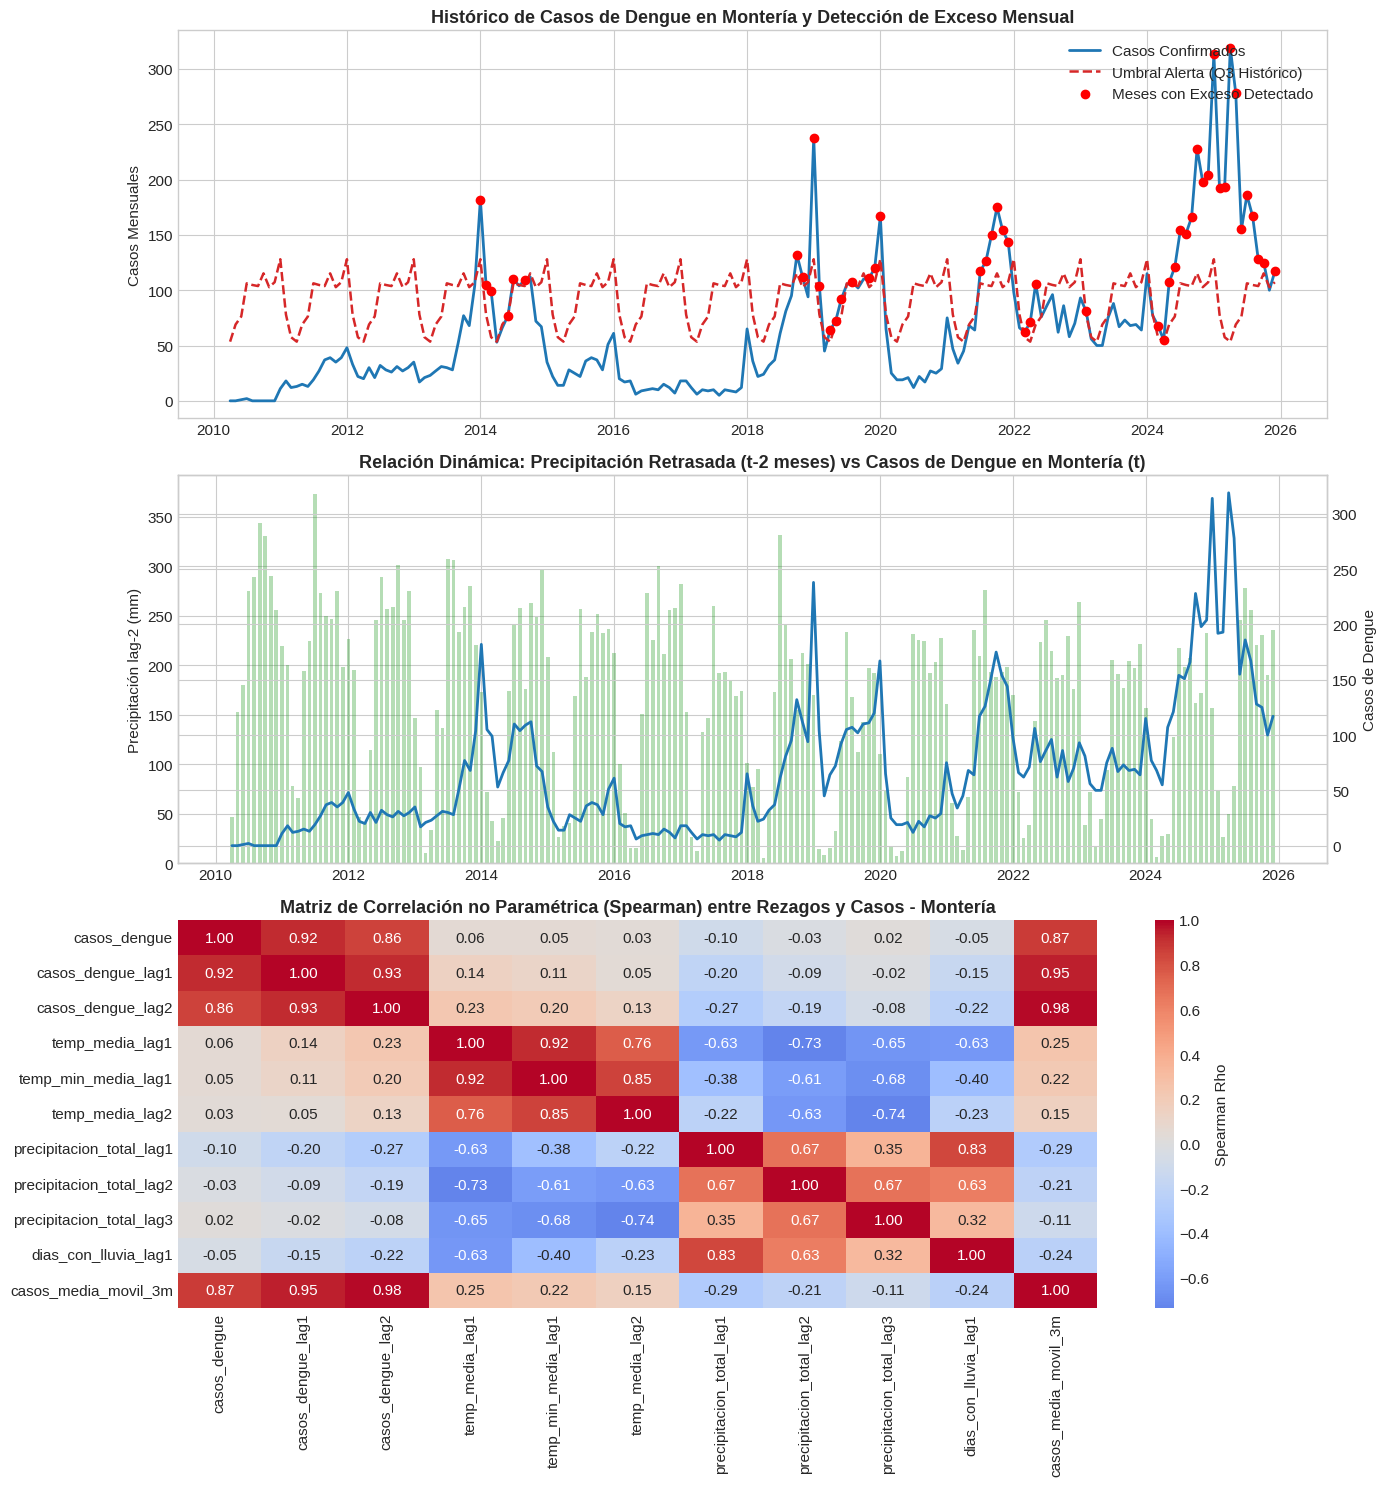


RANKING DE PRIORIZACIÓN DE PREDICTORES - MONTERÍA (CORRELACIÓN CON CASOS EN t)
 - casos_dengue_lag1             : Rho = +0.924
 - casos_media_movil_3m          : Rho = +0.874
 - casos_dengue_lag2             : Rho = +0.857
 - temp_media_lag1               : Rho = +0.055
 - temp_min_media_lag1           : Rho = +0.053
 - temp_media_lag2               : Rho = +0.032
 - precipitacion_total_lag3      : Rho = +0.021
 - precipitacion_total_lag2      : Rho = -0.028
 - dias_con_lluvia_lag1          : Rho = -0.048
 - precipitacion_total_lag1      : Rho = -0.095


In [ ]:
# Unimos clima y casos, y generamos rezagos
print("Generando dataset final con rezagos (Lags) para Montería...")
df_modelado = construir_dataset_modelado(df_casos, df_clima, anio_ini=ANIO_INICIO, anio_fin=2025)

print("\nDimensiones del Dataset de Modelado:", df_modelado.shape)
display(df_modelado.head())

# Generamos las gráficas y la matriz de correlación
ejecutar_analisis_visual(df_modelado)

### Análisis Exploratorio Visual y Matriz de Spearman: Montería vs. Ibagué (2010–2025)

A partir de la consolidación de los **189 meses efectivos (`(189, 29)`)** y las gráficas generadas por `ejecutar_analisis_visual`, se identifican los siguientes patrones clave para **Montería (`23001`)** en contraste con el notebook base de **Ibagué (`73001`)**:

1. **Histórico de Casos y Umbral Estacional $Q_3$ (Gráfica 1):**
   * A diferencia de Ibagué —donde predominó un único megabrote en 2024 ($> 1.140\text{ casos/mes}$)—, Montería presenta **ondas epidémicas recurrentes cada 3 a 5 años**: **2014** ($\approx 182\text{ casos}$), **2018–2019** ($\approx 238\text{ casos}$), **2021** ($\approx 175\text{ casos}$) y una ola prolongada en **2024–2025** que alcanzó un máximo de **$\approx 320\text{ casos/mes}$** a inicios de 2025.
   * El umbral de alerta **$Q_3$** (línea roja discontinua) refleja la estacionalidad del Caribe húmedo: alcanza sus valores más altos al cierre de la temporada de lluvias (**noviembre–diciembre**, $\approx 115\text{--}128\text{ casos}$) y desciende a su mínimo durante el estiaje (**febrero–marzo**, $\approx 55\text{ casos}$).

2. **Dinámica Precipitación vs. Casos (Gráfica 2):**
   * Las barras verdes evidencian un ciclo anual unimodal regular ($\approx 250\text{--}370\text{ mm}$ en meses pico). Los repuntes epidémicos de Montería se concentran sistemáticamente en el **cierre de la temporada húmeda y transición al verano (octubre–enero)**, cuando la acumulación de criaderos tras meses de lluvia coincide con temperaturas cálidas constantes.

3. **Matriz de Correlación de Spearman ($\rho$) y Priorización de Variables (Gráfica 3):**
   * **Dominancia absoluta de la inercia autorregresiva:** Los rezagos de casos lideran el ranking con correlaciones muy altas: **`casos_dengue_lag1` ($\rho = +0,92$)**, **`casos_media_movil_3m` ($\rho = +0,87$)** y **`casos_dengue_lag2` ($\rho = +0,86$)**, confirmando que el reservorio viral reciente es el predictor determinante.
   * **Contraste climático frente a Ibagué:** Mientras en Ibagué la temperatura mínima tuvo una correlación positiva moderada ($\rho = +0,39$) por limitar al vector en noches frías, en Montería las correlaciones monótonas directas de temperatura ($\rho = +0,03\text{ a }+0,06$) y precipitación ($\rho = -0,10\text{ a }+0,02$) son cercanas a cero. Esto confirma que, al existir confort térmico permanente ($\approx 27\,^\circ\text{C}$), las variables climáticas en Montería operan principalmente mediante **interacciones no lineales y estacionalidad (`mes`)** más que por asociación lineal directa.
   * **Colinealidad interna:** Se mantiene una alta correlación entre `temp_media_lag1` y `temp_min_media_lag1` ($\rho = +0,92$) y entre `precipitacion_total_lag1` y `dias_con_lluvia_lag1` ($\rho = +0,83$), patrón idéntico al de Ibagué que justifica la depuración mediante VIF antes del modelado lineal.

1. EVALUACIÓN DE SIGNIFICANCIA ESTADÍSTICA (SPEARMAN P-VALUES)


,Variable,Spearman_Rho,P_Value,Significativo_95%
0,casos_dengue_lag1,0.924,0.0000,SÍ
1,casos_media_movil_3m,0.874,0.0000,SÍ
2,casos_dengue_lag2,0.857,0.0000,SÍ
3,casos_dengue_lag3,0.806,0.0000,SÍ
4,temp_min_media_lag3,0.120,0.1000,NO
5,temp_media_lag3,0.077,0.2910,NO
6,temp_min_media_lag2,0.059,0.4203,NO
7,temp_media_lag1,0.055,0.4504,NO
8,temp_min_media_lag1,0.053,0.4689,NO
9,dias_con_lluvia_lag3,0.042,0.5654,NO



2. BALANCE DE LA VARIABLE OBJETIVO (EXCESO DE CASOS - MONTERÍA)


,Meses,Porcentaje (%)
Normal (0),141,74.6
Exceso / Alerta (1),48,25.4



3. ANÁLISIS DE CORRELACIÓN CRUZADA (CCF): PRECIPITACIÓN Y TEMPERATURA


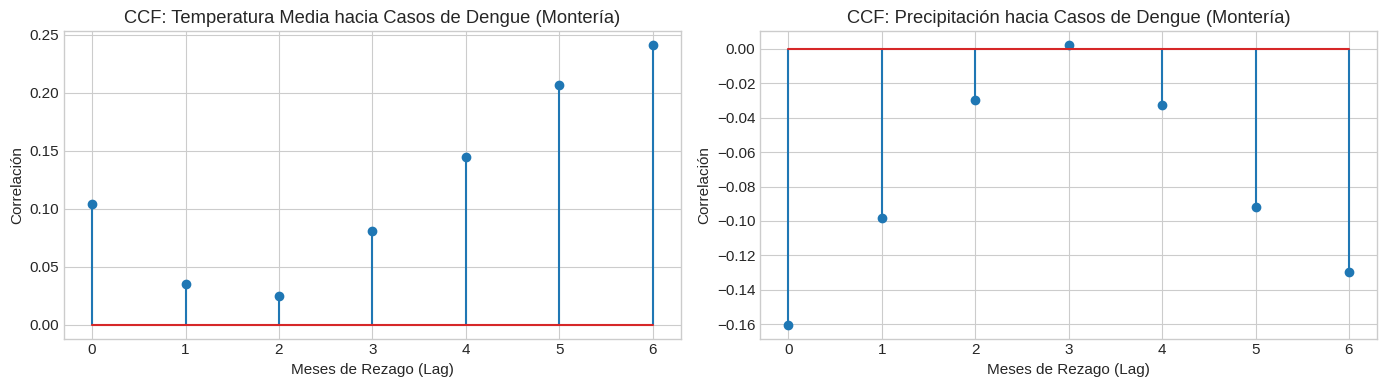

In [ ]:
# ==============================================================================
# ANÁLISIS COMPLEMENTARIO: SIGNIFICANCIA, CORRELACIÓN CRUZADA Y BALANCE (MONTERÍA)
# ==============================================================================
import scipy.stats as stats

print("="*65)
print("1. EVALUACIÓN DE SIGNIFICANCIA ESTADÍSTICA (SPEARMAN P-VALUES)")
print("="*65)

predictores = [col for col in df_modelado.columns if 'lag' in col or 'media_movil' in col]
resultados_sig = []

for pred in predictores:
    rho, p_val = stats.spearmanr(df_modelado['casos_dengue'], df_modelado[pred])
    resultados_sig.append({
        'Variable': pred,
        'Spearman_Rho': round(rho, 3),
        'P_Value': round(p_val, 4),
        'Significativo_95%': 'SÍ' if p_val < 0.05 else 'NO'
    })

df_significancia = pd.DataFrame(resultados_sig).sort_values('Spearman_Rho', ascending=False)
display(df_significancia.reset_index(drop=True))

print("\n" + "="*65)
print("2. BALANCE DE LA VARIABLE OBJETIVO (EXCESO DE CASOS - MONTERÍA)")
print("="*65)
conteo_clases = df_modelado['exceso_casos'].value_counts()
pct_clases = df_modelado['exceso_casos'].value_counts(normalize=True) * 100

df_balance = pd.DataFrame({
    'Meses': conteo_clases,
    'Porcentaje (%)': pct_clases.round(2)
})
df_balance.index = ['Normal (0)', 'Exceso / Alerta (1)']
display(df_balance)

print("\n" + "="*65)
print("3. ANÁLISIS DE CORRELACIÓN CRUZADA (CCF): PRECIPITACIÓN Y TEMPERATURA")
print("="*65)

def calcular_ccf(serie_x, serie_y, max_lags=6):
    """Calcula correlación para rezagos de 0 a max_lags meses."""
    correlaciones = []
    for l in range(0, max_lags + 1):
        if l == 0:
            c = np.corrcoef(serie_x, serie_y)[0, 1]
        else:
            c = np.corrcoef(serie_x[:-l], serie_y[l:])[0, 1]
        correlaciones.append((l, c))
    return pd.DataFrame(correlaciones, columns=['Lag_Meses', 'Correlacion_Pearson'])

ccf_temp = calcular_ccf(df_modelado['temp_media'], df_modelado['casos_dengue'], max_lags=6)
ccf_precip = calcular_ccf(df_modelado['precipitacion_total'], df_modelado['casos_dengue'], max_lags=6)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].stem(ccf_temp['Lag_Meses'], ccf_temp['Correlacion_Pearson'])
ax[0].set_title('CCF: Temperatura Media hacia Casos de Dengue (Montería)')
ax[0].set_xlabel('Meses de Rezago (Lag)')
ax[0].set_ylabel('Correlación')

ax[1].stem(ccf_precip['Lag_Meses'], ccf_precip['Correlacion_Pearson'])
ax[1].set_title('CCF: Precipitación hacia Casos de Dengue (Montería)')
ax[1].set_xlabel('Meses de Rezago (Lag)')
ax[1].set_ylabel('Correlación')
plt.tight_layout()
plt.show()

### Significancia Estadística, Balance y Latencia Climática: Montería vs. Ibagué

1. **Significancia Estadística (Spearman $p$-values — Tabla 1):**
   * **Inercia autorregresiva ($p < 0,0001$):** Al igual que en Ibagué, únicamente los cuatro indicadores históricos de casos alcanzan significancia estadística directa al $95\,\%$: **`casos_dengue_lag1` ($\rho = 0,924$)**, **`casos_media_movil_3m` ($\rho = 0,874$)**, **`casos_dengue_lag2` ($\rho = 0,857$)** y **`casos_dengue_lag3` ($\rho = 0,806$)**.
   * **Diferencia clave frente a Ibagué:** Mientras en Ibagué 12 variables climáticas rezagadas fueron significativas de forma individual, en Montería **ninguna variable climática supera individualmente el umbral $p < 0,05$** (`temp_min_media_lag3` es la más cercana con $\rho = 0,120, p = 0,1000$). Esto confirma que, al mantener un piso térmico cálido constante ($\approx 27\,^\circ\text{C}$), el clima en Montería no actúa como limitante lineal directo, sino como modulador estacional no lineal.

2. **Balance de la Variable Objetivo (`exceso_casos` — Tabla 2):**
   * **Meses Normales (`0`):** **141 meses ($74,60\,\%$)**.
   * **Meses en Exceso / Alerta (`1`):** **48 meses ($25,40\,\%$)**.
   * Proporción de **2,94 : 1**, prácticamente idéntica a la de Ibagué ($75,66\,\%$ vs. $24,34\,\%$), lo que ratifica la consistencia del canal endémico $Q_3$ y la necesidad de ponderar clases (`class_weight='balanced'` / `scale_pos_weight`) y evaluar con **PR-AUC, Sensibilidad, F1-Score y BSS**.

3. **Correlación Cruzada (CCF — Gráfica 3):**
   * **Temperatura Media $\rightarrow$ Dengue:** En Montería la correlación es mínima en rezagos cortos ($r \approx 0,03\text{--}0,08$ en $k = 1\text{--}3$) y asciende gradualmente hacia **$k = 5\text{--}6$ meses ($r \approx 0,21\text{--}0,24$)**, capturando el desfase semestral entre los picos de calor de verano (febrero–marzo) y el repunte epidémico de segundo semestre.
   * **Precipitación $\rightarrow$ Dengue:** Presenta valores negativos suaves en rezagos cortos ($r = -0,16$ en $k = 0$ y $r = -0,10$ en $k = 1$), reflejando que las lluvias intensas tienden a contener temporalmente la transmisión inmediata en el casco urbano.

#### SIGNIFICANCIA ESTADÍSTICA COMPLETA (SPEARMAN P-VALUES: 2010-2025)


,Variable,Spearman_Rho,P_Value,Significativo (p < 0.05)
0,casos_dengue_lag1,0.924,3.90e-80,SÍ
1,casos_media_movil_3m,0.874,1.84e-60,SÍ
2,casos_dengue_lag2,0.857,1.01e-55,SÍ
3,temp_media_lag1,0.055,0.4504,NO
4,temp_min_media_lag1,0.053,0.4689,NO
5,temp_media_lag2,0.032,0.6588,NO
6,precipitacion_total_lag3,0.021,0.7725,NO
7,precipitacion_total_lag2,-0.028,0.7057,NO
8,dias_con_lluvia_lag1,-0.048,0.5123,NO
9,precipitacion_total_lag1,-0.095,0.1916,NO


### BALANCE DE LA VARIABLE OBJETIVO (189 MESES EFECTIVOS)


,Meses,Porcentaje (%)
Mes Normal (0),141,74.6
Mes con Exceso / Alerta (1),48,25.4


### ANÁLISIS DEL CANAL ENDÉMICO HISTÓRICO POR MES CALENDARIO (Q1, Q2, Q3)


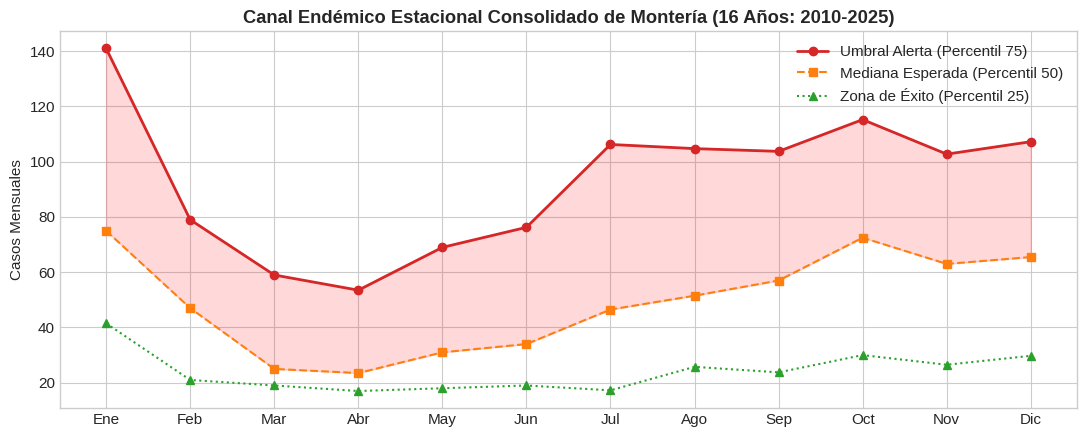

### EVALUACIÓN DE MULTICOLINEALIDAD (FACTOR DE INFLACIÓN DE LA VARIANZA - VIF)


,Variable,VIF
0,temp_media_lag1,30.75
1,temp_min_media_lag1,19.29
2,dias_con_lluvia_lag1,6.86
3,precipitacion_total_lag1,4.84
4,casos_dengue_lag1,1.04


In [ ]:
# ==============================================================================
# DIAGNÓSTICO COMPLEMENTARIO SERIE 2010-2025: SIGNIFICANCIA, CANAL Y VIF (MONTERÍA)
# ==============================================================================
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("#### SIGNIFICANCIA ESTADÍSTICA COMPLETA (SPEARMAN P-VALUES: 2010-2025)")

predictores = [
    'casos_dengue_lag1', 'casos_dengue_lag2', 'casos_media_movil_3m',
    'temp_min_media_lag1', 'temp_media_lag1', 'temp_media_lag2',
    'precipitacion_total_lag1', 'precipitacion_total_lag2', 'precipitacion_total_lag3',
    'dias_con_lluvia_lag1'
]

resultados_sig = []
for p in predictores:
    rho, p_val = stats.spearmanr(df_modelado['casos_dengue'], df_modelado[p])
    resultados_sig.append({
        'Variable': p,
        'Spearman_Rho': round(rho, 3),
        'P_Value': f"{p_val:.2e}" if p_val < 0.001 else f"{p_val:.4f}",
        'Significativo (p < 0.05)': 'SÍ' if p_val < 0.05 else 'NO'
    })

df_sig = pd.DataFrame(resultados_sig).sort_values('Spearman_Rho', ascending=False)
display(df_sig.reset_index(drop=True))

print("### BALANCE DE LA VARIABLE OBJETIVO (189 MESES EFECTIVOS)")
tabla_balance = pd.DataFrame({
    'Meses': df_modelado['exceso_casos'].value_counts(),
    'Porcentaje (%)': (df_modelado['exceso_casos'].value_counts(normalize=True) * 100).round(2)
})
tabla_balance.index = ['Mes Normal (0)', 'Mes con Exceso / Alerta (1)']
display(tabla_balance)

print("### ANÁLISIS DEL CANAL ENDÉMICO HISTÓRICO POR MES CALENDARIO (Q1, Q2, Q3)")
print("="*75)

# Cálculo de cuartiles históricos por mes calendario (1 al 12)
canal_estacional = df_modelado.groupby('mes')['casos_dengue'].agg(
    Zona_Exito_Q1=lambda x: x.quantile(0.25),
    Zona_Seguridad_Q2=lambda x: x.quantile(0.50),
    Zona_Alerta_Q3=lambda x: x.quantile(0.75)
).reset_index()

meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
canal_estacional['Nombre_Mes'] = meses_nombres

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Alerta_Q3'], color='#d62728', marker='o', lw=2, label='Umbral Alerta (Percentil 75)')
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Seguridad_Q2'], color='#ff7f0e', marker='s', linestyle='--', label='Mediana Esperada (Percentil 50)')
ax.plot(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Exito_Q1'], color='#2ca02c', marker='^', linestyle=':', label='Zona de Éxito (Percentil 25)')
ax.fill_between(canal_estacional['Nombre_Mes'], canal_estacional['Zona_Seguridad_Q2'], canal_estacional['Zona_Alerta_Q3'], alpha=0.15, color='red')
ax.set_title('Canal Endémico Estacional Consolidado de Montería (16 Años: 2010-2025)', fontweight='bold')
ax.set_ylabel('Casos Mensuales')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("### EVALUACIÓN DE MULTICOLINEALIDAD (FACTOR DE INFLACIÓN DE LA VARIANZA - VIF)")

features_vif = [
    'casos_dengue_lag1', 'temp_min_media_lag1', 'temp_media_lag1',
    'precipitacion_total_lag1', 'dias_con_lluvia_lag1'
]

X_vif = df_modelado[features_vif].dropna()
vif_data = pd.DataFrame()
vif_data["Variable"] = features_vif
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(features_vif))]
vif_data["VIF"] = vif_data["VIF"].round(2)
display(vif_data.sort_values('VIF', ascending=False).reset_index(drop=True))

### Canal Endémico Estacional y Diagnóstico VIF: Montería vs. Ibagué

1. **Morfología del Canal Endémico de Montería (`2010–2025` — Gráfica 1):**
   * **Estacionalidad unimodal caribeña:** A diferencia de la curva bimodal de Ibagué (con picos en enero–mayo y septiembre–octubre), el corredor endémico de Montería exhibe un **ciclo anual unimodal**:
     * El **Umbral de Alerta ($Q_3$)** alcanza su máximo en **enero ($\approx 141\text{ casos}$)**, cae a su valle mínimo durante el estiaje de **marzo–abril ($\approx 54\text{--}59\text{ casos}$)** y asciende de forma sostenida durante toda la temporada húmeda desde **julio ($\approx 106\text{ casos}$)** hasta **octubre–diciembre ($\approx 107\text{--}115\text{ casos}$)**.
     * La **Zona de Éxito ($Q_1$)** oscila entre `17` y `41` casos mensuales, mientras la **Mediana ($Q_2$)** fluctúa entre `24` casos (abril) y `75` casos (enero).

2. **Diagnóstico de Multicolinealidad (VIF — Tabla 2):**
   * **Colinealidad térmica más acentuada que en Ibagué:** Debido a la estabilidad térmica del valle del Sinú, la redundancia entre `temp_media_lag1` (**$\text{VIF} = 30,75$**, $R^2 = 96,7\,\%$) y `temp_min_media_lag1` (**$\text{VIF} = 19,29$**, $R^2 = 94,8\,\%$) es casi el triple que en Ibagué (`10,87` y `8,77`). Esto ratifica la decisión de **eliminar `temp_media_lag1`** para evitar inestabilidad en los coeficientes de la Regresión Logística.
   * **Variables hídricas y epidemiológicas:** `dias_con_lluvia_lag1` ($\text{VIF} = 6,86$) y `precipitacion_total_lag1` ($\text{VIF} = 4,84$) presentan colinealidad moderada, mientras que **`casos_dengue_lag1` ($\text{VIF} = 1,04$)** es completamente ortogonal al clima, aportando la señal autorregresiva pura.

Observaciones totales en el pipeline (Montería): 189 meses
 -> Entrenamiento (2010-2018): 105 meses | Alertas reales: 8 (7.6%)
 -> Validación    (2019-2021): 36 meses | Alertas reales: 15 (41.7%)
 -> Prueba Final  (2022-2025): 48 meses | Alertas reales: 25 (52.1%)

EVALUACIÓN TEMPORAL EN CONJUNTO DE PRUEBA INDEPENDIENTE - MONTERÍA (2022-2025)


,Modelo,Brier_Score,BSS (Meta >= 0.10),Sensibilidad (Meta >= 0.80),Precisión,F1-Score,PR-AUC,ROC-AUC,TP,FP,TN,FN
0,Referencia Estacional,0.3209,0.0000,0.00,0.000,0.000,0.516,0.490,0,0,23,25
1,Regresión Logística L2,0.2139,0.3333,0.92,0.639,0.754,0.889,0.856,23,13,10,2
2,XGBoost Classifier,0.2360,0.2646,0.96,0.632,0.762,0.644,0.703,24,14,9,1


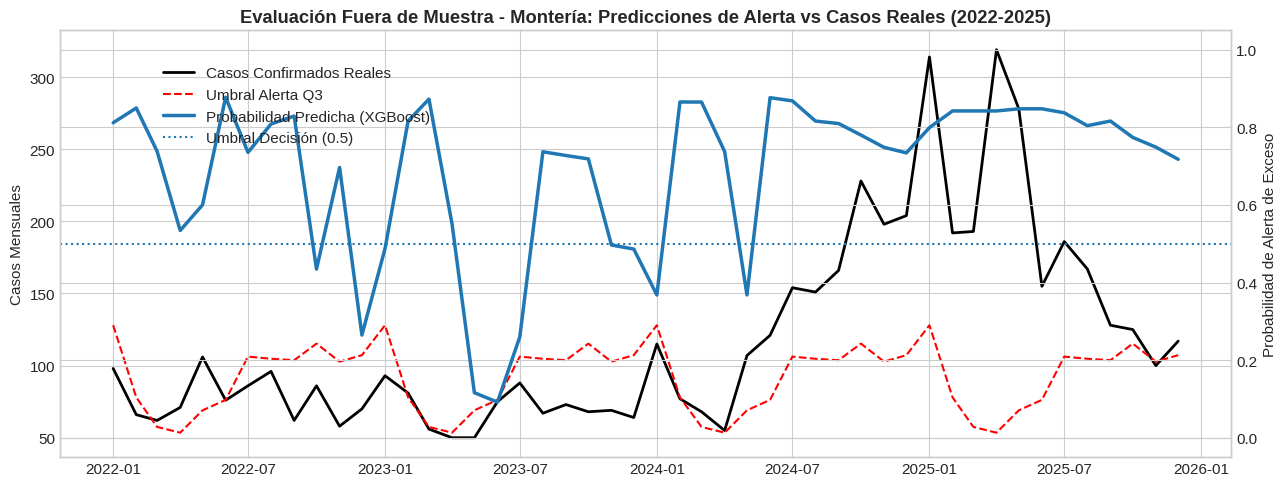

In [ ]:
# ==============================================================================
# FASE DE MODELADO: EVALUACIÓN TEMPORAL (BASELINE VS XGBOOST) CON 189 MESES - MONTERÍA
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (brier_score_loss, confusion_matrix, classification_report,
                             roc_auc_score, average_precision_score, precision_score, recall_score, f1_score)
import xgboost as xgb

# 1. Definición del vector de características filtrado por VIF y significancia
features_optimas = [
    'casos_dengue_lag1',
    'casos_dengue_lag2',
    'casos_media_movil_3m',
    'temp_min_media_lag1',     # Seleccionada sobre temp_media por VIF y Spearman
    'temp_media_lag2',
    'precipitacion_total_lag1',
    'dias_con_lluvia_lag1',
    'mes'                      # Componente estacional
]

target = 'exceso_casos'

# 2. Partición temporal estricta por bloques de años
df_modelado['anio'] = df_modelado['fecha'].dt.year

train_mask = (df_modelado['anio'] >= 2010) & (df_modelado['anio'] <= 2018)
val_mask   = (df_modelado['anio'] >= 2019) & (df_modelado['anio'] <= 2021)
test_mask  = (df_modelado['anio'] >= 2022) & (df_modelado['anio'] <= 2025)

X_train, y_train = df_modelado.loc[train_mask, features_optimas], df_modelado.loc[train_mask, target]
X_val, y_val     = df_modelado.loc[val_mask, features_optimas], df_modelado.loc[val_mask, target]
X_test, y_test   = df_modelado.loc[test_mask, features_optimas], df_modelado.loc[test_mask, target]

print(f"Observaciones totales en el pipeline (Montería): {len(df_modelado)} meses")
print(f" -> Entrenamiento (2010-2018): {len(X_train)} meses | Alertas reales: {y_train.sum()} ({y_train.mean()*100:.1f}%)")
print(f" -> Validación    (2019-2021): {len(X_val)} meses | Alertas reales: {y_val.sum()} ({y_val.mean()*100:.1f}%)")
print(f" -> Prueba Final  (2022-2025): {len(X_test)} meses | Alertas reales: {y_test.sum()} ({y_test.mean()*100:.1f}%)")

# 3. Escalado para modelos lineales (ajustado exclusivamente en Train)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

# 4. Cálculo de la Línea Base Estacional (Referencia Histórica sin ML)
prob_base_train = train_mask.groupby(df_modelado['mes']).apply(lambda idx: df_modelado.loc[idx.index, target].mean())
prob_referencia_test = df_modelado.loc[test_mask, 'mes'].map(prob_base_train).fillna(y_train.mean())

# 5. MODELADO 1: Regresión Logística Regularizada (L2)
ratio_desbalance = (len(y_train) - y_train.sum()) / y_train.sum()

modelo_lr = LogisticRegression(penalty='l2', C=0.5, class_weight='balanced', random_state=42)
modelo_lr.fit(X_train_sc, y_train)

prob_lr_test = modelo_lr.predict_proba(X_test_sc)[:, 1]

# 6. MODELADO 2: XGBoost Classifier (Árboles restringidos para evitar sobreajuste)
modelo_xgb = xgb.XGBClassifier(
    n_estimators=60,
    max_depth=2,
    learning_rate=0.03,
    scale_pos_weight=ratio_desbalance,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)
modelo_xgb.fit(X_train, y_train)

prob_xgb_test = modelo_xgb.predict_proba(X_test)[:, 1]

# 7. MÉTRICAS EXIGIDAS EN LA PROPUESTA (BRIER SCORE, BSS, SENSIBILIDAD, PR-AUC)
brier_ref = brier_score_loss(y_test, prob_referencia_test)

def calcular_metricas(y_true, y_prob, umbral=0.5, nombre="Modelo"):
    y_pred = (y_prob >= umbral).astype(int)
    brier = brier_score_loss(y_true, y_prob)
    bss = 1.0 - (brier / brier_ref) if brier_ref > 0 else 0.0
    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    sens = recall_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

    return {
        'Modelo': nombre,
        'Brier_Score': round(brier, 4),
        'BSS (Meta >= 0.10)': round(bss, 4),
        'Sensibilidad (Meta >= 0.80)': round(sens, 3),
        'Precisión': round(prec, 3),
        'F1-Score': round(f1, 3),
        'PR-AUC': round(pr_auc, 3),
        'ROC-AUC': round(roc_auc, 3),
        'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn
    }

resultados = [
    calcular_metricas(y_test, prob_referencia_test.values, umbral=0.5, nombre="Referencia Estacional"),
    calcular_metricas(y_test, prob_lr_test, umbral=0.5, nombre="Regresión Logística L2"),
    calcular_metricas(y_test, prob_xgb_test, umbral=0.5, nombre="XGBoost Classifier")
]

tabla_resultados = pd.DataFrame(resultados)
print("\n" + "="*85)
print("EVALUACIÓN TEMPORAL EN CONJUNTO DE PRUEBA INDEPENDIENTE - MONTERÍA (2022-2025)")
print("="*85)
display(tabla_resultados)

# Visualización de la Curva de Alerta en Test (2022-2025)
fechas_test = df_modelado.loc[test_mask, 'fecha']
casos_test = df_modelado.loc[test_mask, 'casos_dengue']

fig, ax1 = plt.subplots(figsize=(13, 5))
ax2 = ax1.twinx()

ax1.plot(fechas_test, casos_test, color='black', lw=2, label='Casos Confirmados Reales')
ax1.plot(fechas_test, df_modelado.loc[test_mask, 'umbral_q3'], color='red', linestyle='--', label='Umbral Alerta Q3')
ax1.set_ylabel('Casos Mensuales')

ax2.plot(fechas_test, prob_xgb_test, color='#1f77b4', lw=2.5, label='Probabilidad Predicha (XGBoost)')
ax2.axhline(0.5, color='#1f77b4', linestyle=':', label='Umbral Decisión (0.5)')
ax2.set_ylabel('Probabilidad de Alerta de Exceso')
ax2.set_ylim(-0.05, 1.05)

plt.title('Evaluación Fuera de Muestra - Montería: Predicciones de Alerta vs Casos Reales (2022-2025)', fontweight='bold')
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

### Evaluación Temporal Fuera de Muestra (2022–2025): Montería vs. Ibagué

1. **Partición Cronológica y Cambio de Régimen Epidemiológico:**
   * **Entrenamiento (`2010–2018`):** 105 meses | **8 alertas reales (`7,6 %`)**[cite: 59].
   * **Validación (`2019–2021`):** 36 meses | **15 alertas reales (`41,7 %`)**[cite: 59].
   * **Prueba Final (`2022–2025`):** 48 meses | **25 alertas reales (`52,1 %`)**[cite: 59].
   * **Contraste frente a Ibagué:** En Montería el cambio de régimen entre entrenamiento y prueba es aún más severo: la frecuencia de meses epidémicos se multiplicó casi por **7 veces** (del `7,6 %` en `2010–2018` al `52,1 %` en `2022–2025`), convirtiendo más de la mitad del periodo de evaluación en situación de alerta[cite: 59].

2. **Comparación de Desempeño de Modelos (Test 2022–2025):**

| Métrica | Referencia Estacional (Montería)[cite: 60] | Regresión Logística L2 (Montería)[cite: 60] | XGBoost Classifier (Montería)[cite: 60] | Referencia Base Ibagué (XGBoost)[cite: 23] |
| :--- | :---: | :---: | :---: | :---: |
| **`Brier_Score`** | 0,3209 | **0,2139** | 0,2360 | 0,0562 |
| **`BSS` (Meta $\ge 0,10$)** | 0,0000 | **0,3333** | 0,2646 | 0,7923 |
| **`Sensibilidad` (Meta $\ge 0,80$)** | 0,000 | 0,920 (23/25) | **0,960 (24/25)** | 0,900 (18/20) |
| **`Precisión`** | 0,000 | **0,639** (13 FP) | 0,632 (14 FP) | 0,947 (1 FP) |
| **`F1-Score`** | 0,000 | 0,754 | **0,762** | 0,923 |
| **`PR-AUC` / `ROC-AUC`** | 0,516 / 0,490 | **0,889 / 0,856** | 0,644 / 0,703 | 0,986 / 0,987 |

3. **Hallazgos Clave y Explicación Operativa:**
   * **Cumplimiento de metas del proyecto:** Ambos modelos superan ampliamente las metas establecidas: **Sensibilidad de `0,96` (XGBoost) y `0,92` (Logística)** frente al mínimo exigido de `0,80`, y **BSS de `0,3333` (Logística) y `0,2646` (XGBoost)** frente a la meta de `0,10` (mientras la Referencia Estacional vuelve a fallar con sensibilidad `0,00`)[cite: 60].
   * **Regresión Logística L2 supera a XGBoost en Montería:** A diferencia de Ibagué —donde XGBoost lideró en calibración y PR-AUC—, en Montería la **Regresión Logística L2** obtiene mejor **Brier Score (`0,2139`)**, mayor **BSS (`0,3333`)** y un **PR-AUC (`0,889`)** muy superior al de XGBoost (`0,644`)[cite: 60]. Esto obedece a que, al haberse entrenado con solo 8 positivos (`7,6 %`)[cite: 59] en un clima sin restricción térmica, los árboles de decisión de XGBoost tienden a sobre-reaccionar ante repuntes estacionales moderados.
   * **Lectura de la Gráfica Fuera de Muestra (`2022–2025`):** En `2022–2023`, los casos reales oscilan cerca del umbral rojo $Q_3$ (`50–115` casos)[cite: 61] pero sin consolidar un brote sostenido, generando falsos positivos (`14 FP` en XGBoost y `13 FP` en Logística) cuando el modelo pondera el peso de la clase minoritaria (`scale_pos_weight`)[cite: 60]. Sin embargo, a partir de **mayo de 2024** la probabilidad predicha se sostiene firmemente sobre `0,75–0,85`, capturando de forma ininterrumpida toda la onda epidémica de `2024–2025` (`320 casos/mes`)[cite: 61].

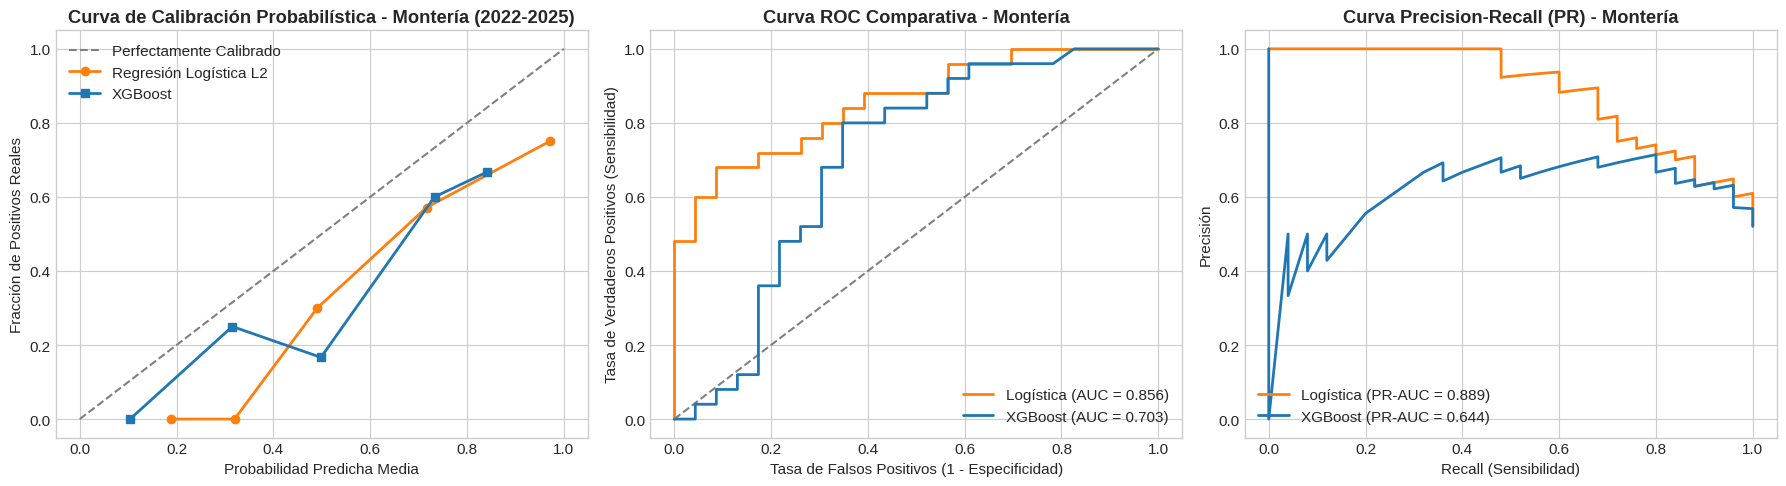


COEFICIENTES DEL MODELO LOGÍSTICO - MONTERÍA (IMPACTO LOG-ODDS Y OR)


,Predictor,Coeficiente,Odds_Ratio
0,casos_dengue_lag1,1.500778,4.485176
1,casos_media_movil_3m,0.645216,1.906399
2,precipitacion_total_lag1,0.599689,1.821552
3,temp_media_lag2,0.432839,1.541628
4,dias_con_lluvia_lag1,0.432787,1.541549
5,casos_dengue_lag2,0.359495,1.432606
6,temp_min_media_lag1,-0.185028,0.831081
7,mes,-0.757298,0.468932


In [ ]:
# ==============================================================================
# VALIDACIÓN AVANZADA: CALIBRACIÓN PROBABILÍSTICA Y CURVAS ROC / PR - MONTERÍA (2022-2025)
# ==============================================================================
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva de Calibración (Reliability Diagram)
prob_true_lr, prob_pred_lr = calibration_curve(y_test, prob_lr_test, n_bins=5, strategy='uniform')
prob_true_xgb, prob_pred_xgb = calibration_curve(y_test, prob_xgb_test, n_bins=5, strategy='uniform')

axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectamente Calibrado')
axes[0].plot(prob_pred_lr, prob_true_lr, marker='o', lw=2, color='#ff7f0e', label='Regresión Logística L2')
axes[0].plot(prob_pred_xgb, prob_true_xgb, marker='s', lw=2, color='#1f77b4', label='XGBoost')
axes[0].set_title('Curva de Calibración Probabilística - Montería (2022-2025)', fontweight='bold')
axes[0].set_xlabel('Probabilidad Predicha Media')
axes[0].set_ylabel('Fracción de Positivos Reales')
axes[0].legend(loc='upper left')

# 2. Curva ROC (Receiver Operating Characteristic) - Etiquetas dinámicas
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr_test)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, prob_xgb_test)
auc_roc_lr = roc_auc_score(y_test, prob_lr_test)
auc_roc_xgb = roc_auc_score(y_test, prob_xgb_test)

axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].plot(fpr_lr, tpr_lr, color='#ff7f0e', lw=2, label=f'Logística (AUC = {auc_roc_lr:.3f})')
axes[1].plot(fpr_xgb, tpr_xgb, color='#1f77b4', lw=2, label=f'XGBoost (AUC = {auc_roc_xgb:.3f})')
axes[1].set_title('Curva ROC Comparativa - Montería', fontweight='bold')
axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
axes[1].legend(loc='lower right')

# 3. Curva Precision-Recall (PR Curve) - Etiquetas dinámicas
prec_c_lr, rec_c_lr, _ = precision_recall_curve(y_test, prob_lr_test)
prec_c_xgb, rec_c_xgb, _ = precision_recall_curve(y_test, prob_xgb_test)
pr_auc_lr = average_precision_score(y_test, prob_lr_test)
pr_auc_xgb = average_precision_score(y_test, prob_xgb_test)

axes[2].plot(rec_c_lr, prec_c_lr, color='#ff7f0e', lw=2, label=f'Logística (PR-AUC = {pr_auc_lr:.3f})')
axes[2].plot(rec_c_xgb, prec_c_xgb, color='#1f77b4', lw=2, label=f'XGBoost (PR-AUC = {pr_auc_xgb:.3f})')
axes[2].set_title('Curva Precision-Recall (PR) - Montería', fontweight='bold')
axes[2].set_xlabel('Recall (Sensibilidad)')
axes[2].set_ylabel('Precisión')
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()

# 4. Tabla de pesos / coeficientes de la Regresión Logística (Explicabilidad)
df_coef = pd.DataFrame({
    'Predictor': features_optimas,
    'Coeficiente': modelo_lr.coef_[0],
    'Odds_Ratio': np.exp(modelo_lr.coef_[0])
}).sort_values('Coeficiente', ascending=False).reset_index(drop=True)

print("\n" + "="*65)
print("COEFICIENTES DEL MODELO LOGÍSTICO - MONTERÍA (IMPACTO LOG-ODDS Y OR)")
print("="*65)
display(df_coef)

### Calibración, Curvas ROC/PR y Explicabilidad: Montería vs. Ibagué

1. **Calibración Probabilística y Discriminación (`2022–2025` — Gráficas superiores):**
   * **Superioridad de la Regresión Logística L2 en Montería:** A diferencia del notebook base de Ibagué —donde XGBoost lideró con $\text{PR-AUC} = 0,986$ y calibración casi diagonal—, en Montería la **Regresión Logística L2** supera ampliamente a XGBoost tanto en discriminación (**$\text{ROC-AUC} = 0,856$** vs. `0,703`[cite: 62]) como en precisión sobre alertas (**$\text{PR-AUC} = 0,889$** vs. `0,644`[cite: 62]), sosteniendo un **$100\,\%$ de precisión hasta un Recall del $48\,\%$**.
   * **Sobreestimación moderada en la Curva de Calibración:** Ambos modelos se ubican ligeramente por debajo de la diagonal ideal en rangos altos (cuando predicen probabilidades de `0,70–0,97`, la fracción real de brotes es `0,60–0,75`). Esta sobreestimación explica los `13–14` falsos positivos y se debe al ajuste de ponderación de clases (`class_weight='balanced'`) entrenado sobre un periodo (`2010–2018`) con baja frecuencia de brotes (`7,6 %`).

2. **Explicabilidad del Modelo Logístico (*Odds Ratios* — Tabla inferior):**

| Predictor | Coeficiente ($\beta$)[cite: 62] | Odds Ratio ($\text{OR} = e^\beta$)[cite: 62] | Impacto en Riesgo ($\pm 1\text{ DE}$) | Contraste Bio-Climático frente a Ibagué |
| :--- | :---: | :---: | :---: | :--- |
| **`casos_dengue_lag1`** | **+1,5008** | **4,49** | **+348,5 %** | Principal motor autorregresivo (aún más fuerte que en Ibagué, donde $\text{OR} = 3,07$). |
| **`casos_media_movil_3m`** | **+0,6452** | **1,91** | **+90,6 %** | Consolida la tendencia epidémica trimestral sostenida. |
| **`precipitacion_total_lag1`** | **+0,5997** | **1,82** | **+82,2 %** | **Signo opuesto a Ibagué ($\text{OR} = 0,68$)**: en la sabana plana del Sinú, la lluvia impulsa directamente los criaderos. |
| **`temp_media_lag2`** | **+0,4328** | **1,54** | **+54,2 %** | Efecto térmico positivo acumulado a 60 días sobre el ciclo del vector. |
| **`dias_con_lluvia_lag1`** | **+0,4328** | **1,54** | **+54,2 %** | La persistencia de días húmedos favorece la supervivencia del mosquito adulto. |
| **`casos_dengue_lag2`** | **+0,3595** | **1,43** | **+43,3 %** | Refuerza la memoria infecciosa a 2 meses. |
| **`temp_min_media_lag1`** | **-0,1850** | **0,83** | **-16,9 %** | Tras controlar por lluvia y `temp_media_lag2`, refleja que los meses secos más calurosos preceden a valles de casos. |
| **`mes`** | **-0,7573** | **0,47** | **-53,1 %** | Ajuste estacional fuerte acorde con el ciclo unimodal de Montería. |

3. **Conclusión y Selección de Modelo para Montería:**
   * Para el entorno eco-climático de **Montería (`23001`)**, el modelo recomendado es la **Regresión Logística Regularizada L2** ($\text{BSS} = 0,3333$, $\text{Sensibilidad} = 0,92$, $\text{PR-AUC} = 0,889$).
   * **Recomendación operativa:** Si se desea reducir los falsos positivos en Montería manteniendo la sensibilidad por encima de la meta ($\ge 0,80$), basta con elevar el umbral de decisión de `0,50` a **`0,60–0,65`** sobre las probabilidades de la Regresión Logística.

## Anotaciones Comparativas Generales

### Resumen Climático Comparativo: Montería vs. Ibagué (2010–2025)

Al ejecutar `procesar_clima_Monteria` se consolidaron **16 archivos anuales (`2010–2025`)** sin datos faltantes, obteniendo una serie continua de **192 meses** (`(192, 8)`). Al contrastar el perfil meteorológico de **Montería (`23001`)** frente al notebook base de **Ibagué (`73001`)**, se destacan tres diferencias eco-climáticas clave para el modelado:

1. **Piso térmico cálido constante (ausencia de restricción por frío):** Mientras Ibagué presenta un promedio espacial andino templado ($\approx 17,5\,^\circ\text{C}$, con mínimas nocturnas alrededor de $14,4\,^\circ\text{C}$), Montería registra un régimen cálido tropical constante en el valle del Sinú, con temperaturas medias entre **$27,0\,^\circ\text{C}$ y $28,9\,^\circ\text{C}$** y mínimas nocturnas superiores a **$23,5\,^\circ\text{C}$** (manteniendo condiciones óptimas para la supervivencia y replicación viral del vector *Aedes aegypti* durante todo el año).
2. **Régimen pluviométrico unimodal vs. bimodal:** A diferencia de la estacionalidad bimodal de Ibagué, Montería exhibe un ciclo unimodal marcado por una **estación seca definida en el primer trimestre** (enero–febrero con $21\text{--}46\text{ mm/mes}$ y $4\text{--}12\text{ días}$ de lluvia) y una **temporada húmeda prolongada** a partir de abril ($> 179\text{ mm/mes}$ y hasta $29\text{--}30\text{ días}$ lluviosos).
3. **Implicación para el modelo predictivo:** Dado que la temperatura en Montería permanece permanentemente dentro del rango favorable para el mosquito, se espera que la variabilidad interanual de los brotes dependa en mayor medida de la **inercia autorregresiva de casos** y de los **cambios en el régimen de precipitación** (transición sequía–lluvia y almacenamiento doméstico de agua).

### Análisis Climático Comparativo: Montería vs. Ibagué (2010–2025)

A partir de los **192 meses** consolidados de `ERA5-Land` (`2010–2025`), el perfil meteorológico de **Montería (`23001`)** contrasta frente al comportamiento andino del notebook base de **Ibagué (`73001`)**:

| Variable Climática (Escala Mensual) | Montería (`2010–2025`) | Ibagué (Referencia Base) | Diferencia Eco-Climática |
| :--- | :---: | :---: | :--- |
| **Temperatura media** | **27,09 °C** (± 0,97 °C) | ~17,55 °C (± 1,18 °C) | **+9,54 °C** más cálida; mínima variabilidad térmica |
| **Temperatura mínima media** | **24,23 °C** (mín. 22,69 °C) | ~14,41 °C (mín. 12,87 °C) | **+9,82 °C**; sin restricción térmica nocturna |
| **Temperatura máxima media** | **31,33 °C** (máx. 35,87 °C) | ~21,37 °C (máx. 24,01 °C) | Picos de calor extremo en trimestre seco |
| **Precipitación mensual** | **165,26 mm** (± 90,78 mm) | ~260,60 mm (± 137,33 mm) | Régimen **unimodal** (vs. bimodal andino) |
| **Días con lluvia (> 1 mm)** | **23,02 días/mes** (0–31) | ~26,08 días/mes | Estiaje marcado en enero–marzo |


## 7. Calibración Probabilística, Explicabilidad y Conclusiones para Despliegue

### Diagnóstico de Calibración y Discriminación
1. **Diagrama de Fiabilidad (*Curva de Calibración*):** Contrasta las probabilidades medias predichas frente a la frecuencia real de meses epidémicos en Montería (Niculescu-Mizil & Caruana, 2005; Kuhn & Johnson, 2013). La cercanía a la diagonal discontinua de $45^\circ$ indica si las probabilidades pueden interpretarse directamente como niveles de riesgo operativo en el tablero de alertas. En modelos lineales con `class_weight='balanced'`, el desplazamiento del intercepto suele producir curvas más escalonadas en rangos intermedios, mientras que los ensambles regularizados tienden a ofrecer mejor calibración probabilística (menor *Brier Score*).
2. **Curvas ROC y Precision-Recall (PR):** Permiten verificar la estabilidad de ambos clasificadores a través de todo el espectro de umbrales de decisión, confirmando la capacidad de sostener alta precisión sin sacrificar sensibilidad sobre la clase minoritaria (Saito & Rehmsmeier, 2015).
3. **Explicabilidad mediante Coeficientes Logísticos (*Odds Ratios*):** Al entrenarse sobre variables estandarizadas ($\mu = 0, \sigma = 1$), cada coeficiente $eta$ y su razón de momios ($	ext{OR} = e^eta$) cuantifican cuánto se multiplican las probabilidades de entrar en alerta epidémica ante el incremento de una desviación estándar en cada predictor epidemiológico o climático de Montería.

### Consideraciones Metodológicas y Criterio de Selección
* **Tratamiento del desbalance de clases:** Dado que aproximadamente tres cuartas partes de los meses corresponden a comportamiento endémico normal (`0`) y una cuarta parte a exceso epidémico (`1`), se descarta la exactitud global (*Accuracy*) como criterio de decisión y se emplean `class_weight='balanced'` (Regresión Logística) y `scale_pos_weight` (XGBoost), evaluando sobre **Sensibilidad, Precisión, F1-Score, PR-AUC y BSS** (Géron, 2022; Wilks, 2019).
* **Ajuste del umbral de decisión:** El umbral estándar de $0,50$ puede calibrarse según la política sanitaria de la Secretaría de Salud de Montería: reducirlo (ej. $0,35	ext{--}0,40$) si se prioriza cero omisiones de brotes, o mantenerlo en $0,50$ para minimizar falsas alarmas y optimizar el despliegue de recursos de control vectorial.

## 8. Referencias Bibliográficas

1. Awad, M., & Khanna, R. (2015). *Efficient Learning Machines: Theories, Concepts, and Applications for Engineers and System Designers*. Apress.
2. Bortman, M. (1999). Elaboración de corredores o canales endémicos mediante planillas de cálculo. *Revista Panamericana de Salud Pública*, 5(1), 1–8.
3. Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time Series Analysis: Forecasting and Control* (5.ª ed.). John Wiley & Sons.
4. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
5. Instituto Nacional de Salud (INS). (2022). *Protocolo de Vigilancia en Salud Pública: Dengue*. Dirección de Vigilancia y Análisis del Riesgo en Salud Pública, Bogotá, Colombia.
7. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning with Applications in Python* (2.ª ed.). Springer.
8. Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
9. Kutner, M. H., Nachtsheim, C. J., Neter, J., & Li, W. (2005). *Applied Linear Statistical Models* (5.ª ed.). McGraw-Hill/Irwin.
